This notebook ('diann_rt_stability_analysis.ipynb') reads and filters the main report from DIANN output (report.parquet), selects runs for defined conditions, and statistically compares retention time (RT) stability (variability) across conditions using per-precursor standard deviations.
Results are visualized as violin plots (standard and clean/outlier-scattered versions) for forward and reverse flush mode, with the underlying statistical analysis performed via the Friedman test and post-hoc Wilcoxon signed-rank tests.

**Workflow overview:**

1. **Setup** – Import packages, set working directory, import custom `diann_main_report_filtering` and `retention_time_stability_stats` modules, enable autoreload, configure pandas display options.
2. **Define paths** – Set `input_dir` / `output_dir` for the dataset to process.
3. **Load report** – Read DIA-NN's `report.parquet` into a pandas DataFrame.
4. **FDR filtering** – Sequentially filter the main report at 1% precursor Q.Value (run-specific and global) and 1% global protein group Q.Value, plus a lenient Quantity.Quality cutoff (≥ 0.5).
5. **Run selection** – Define forward and reverse flush run lists per condition (pepmap, nanoshield_tht021_flip, direct_injection) and subset the filtered report into `main_report_pd_fil_for` / `main_report_pd_fil_rev`.
6. **Condition assignment & shared-precursor filtering** – Map acquisition dates to condition names, then restrict each flush dataset to precursors present in all runs.
7. **Per-precursor summary** – Summarize RT values per precursor per condition, computing the SD (variability) to avoid pseudoreplication from pairwise RT_Delta values.
8. **Omnibus & post-hoc testing** – Run the Friedman test (with Kendall's W) on the per-precursor SD values across conditions, followed by Holm-corrected post-hoc Wilcoxon signed-rank tests if significant.
9. **Visualization** – Plot the same SD data used in the statistics as standard violin plots and as clean violin plots with outliers shown as jittered scatter points, separately for forward and reverse flush mode.
10. **Stability ranking** – Print a ranking of conditions by RT stability for each flush mode.

In [1]:
# import relevant packages
import sys
import os
import inspect
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from pathlib import Path
from textwrap import dedent

# change working direction - point to where your notebooks (.ipynb) and python files (.py) are placed
new_cwd = Path("Z:/user/Dennis/trap_column_test/manuscript/diann_processing/jupyter_notebooks/github/")
os.chdir(new_cwd)
# verify new working directory
print("Current working directory:\n",os.getcwd())

# import custom functions
import diann_main_report_filtering as diann_filter
import retention_time_stability as rts

# auto reload of imported packages
%load_ext autoreload
%autoreload 2

# check where python is looking for path to resolve imports and where it actually loaded the packages from
print(f"This is where python is looking for packages:\n{sys.path}\n")

# change display settings for pandas dataframes
pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)
pd.set_option("display.max_colwidth", None)

# set to back to default if needed
#pd.reset_option("display.max_columns")
#pd.reset_option("display.max_rows")
    
# check current working directory of this notebook
print("Current working directory:")
!pwd

Current working directory:
 Z:\user\Dennis\trap_column_test\manuscript\diann_processing\jupyter_notebooks\github
This is where python is looking for packages:
['C:\\Users\\dennis.dannecker\\AppData\\Local\\anaconda3\\envs\\trap_column_test\\python313.zip', 'C:\\Users\\dennis.dannecker\\AppData\\Local\\anaconda3\\envs\\trap_column_test\\DLLs', 'C:\\Users\\dennis.dannecker\\AppData\\Local\\anaconda3\\envs\\trap_column_test\\Lib', 'C:\\Users\\dennis.dannecker\\AppData\\Local\\anaconda3\\envs\\trap_column_test', '', 'C:\\Users\\dennis.dannecker\\AppData\\Local\\anaconda3\\envs\\trap_column_test\\Lib\\site-packages', 'C:\\Users\\dennis.dannecker\\AppData\\Local\\anaconda3\\envs\\trap_column_test\\Lib\\site-packages\\win32', 'C:\\Users\\dennis.dannecker\\AppData\\Local\\anaconda3\\envs\\trap_column_test\\Lib\\site-packages\\win32\\lib', 'C:\\Users\\dennis.dannecker\\AppData\\Local\\anaconda3\\envs\\trap_column_test\\Lib\\site-packages\\Pythonwin']

Current working directory:
/z/user/Dennis/t

In [2]:
# define input and output directories for each acquired dataset

input_dir = Path("Z:/user/Dennis/trap_column_test/manuscript/diann_processing/dataset_g_combined/")
output_dir = Path("Z:/user/Dennis/trap_column_test/manuscript/diann_processing/dataset_g_combined/github_test/rt_stability_analysis/")

In [3]:
# read dianns main output parquet file as a pandas dataframe

# define input file name
input_file_name = "report.parquet"
# define input file path
input_file_path = input_dir / input_file_name
# read parquet file as pd dataframe
main_report_pd = pd.read_parquet(input_file_path, engine='pyarrow')
print("DIANN's parquet file was read in as a pandas dataframe.")

DIANN's parquet file was read in as a pandas dataframe.


In [4]:
# perform basic FDR filtering of loaded main report, "main_report_pd"

# filters sequentially, overwriting the variable to save memory
main_report_pd_fil = diann_filter.filter_dataframe(df=main_report_pd, column="Q.Value", cutoff=0.01, smaller_than=True, filter_proteotypic=False) # default precursor filtering at 1%, run-specific
main_report_pd_fil = diann_filter.filter_dataframe(df=main_report_pd_fil, column="Global.Q.Value", cutoff=0.01, smaller_than=True, filter_proteotypic=False) # precursor filtering at 1%, global
main_report_pd_fil = diann_filter.filter_dataframe(df=main_report_pd_fil, column="Global.PG.Q.Value", cutoff=0.01, smaller_than=True, filter_proteotypic=False) # protein group filtering at 1%, global
# lenient, retain the vast majority of IDs, drop only clearly bad ones - quality of precursor quantity, is it trustworthy
main_report_pd_fil = diann_filter.filter_dataframe(df=main_report_pd_fil, column="Quantity.Quality", cutoff=0.5, smaller_than=False, filter_proteotypic=False)
# reset index after filtering to maintain a clean sequence
main_report_pd_fil.reset_index(drop=True, inplace=True)
print("Dataframe was filtered successfully")

Dataframe was filtered successfully


In [5]:
# higher level conditions and run selection

# define selected runs
run_sel_for = [
  # pepmap - forward
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_for_1",
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_for_2",
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_for_3",
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_for_4",
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_for_5",
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_for_6",
  # nanoshield tht021 flipped - forward
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_for_1",
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_for_2",
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_for_3",
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_for_4",
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_for_5",
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_for_6",
  # direct injection
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_1",
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_2",
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_3",
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_4",
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_5",
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_6", 
]

run_sel_rev = [
  # pepmap - reverse
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_rev_1",
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_rev_2",
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_rev_3",
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_rev_4",
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_rev_5",
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_rev_6",
  # nanoshield tht021 flipped - reverse
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_rev_1",
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_rev_2",
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_rev_3",
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_rev_4",
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_rev_5",
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_rev_6",
  # direct injection
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_1",
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_2",
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_3",
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_4",
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_5",
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_6", 
]

# select runs from main report using exact matching for "Run" name - main_report_pd_fil_for is main dataframe used for all analyses below - forward
main_report_pd_fil_for = main_report_pd_fil[main_report_pd_fil["Run"].isin(run_sel_for)].copy()
print("Selection is done - forward")
# select runs from main report using exact matching for "Run" name - main_report_pd_fil_rev is main dataframe used for all analyses below - reverse
main_report_pd_fil_rev = main_report_pd_fil[main_report_pd_fil["Run"].isin(run_sel_rev)].copy()
print("Selection is done - reverse")

Selection is done - forward
Selection is done - reverse


Filtering for precursors present in all runs is done - forward: 9934 unique precursors
Filtering for precursors present in all runs is done - reverse: 17086 unique precursors


########## FORWARD ##########

[forward] Precursors with complete SD data across all 3 conditions: 9934

=== Friedman test: forward — RT variability (SD) ===
Friedman chi2 = 7011.5359, df = 2, p = 0
Kendall's W (effect size) = 0.3529

--> Significant global difference detected. Running post-hoc pairwise Wilcoxon signed-rank tests (Holm-corrected):
                                Comparison  Wilcoxon_stat         p_raw        p_holm  effect_size_r  significant_holm
          pepmap vs nanoshield_tht021_flip      6846562.0  0.000000e+00  0.000000e+00      -0.722514              True
                pepmap vs direct_injection      2705867.0  0.000000e+00  0.000000e+00      -0.890333              True
nanoshield_tht021_flip vs direct_injection     14113953.5 9.807302e-299 9.807302e-299      -0.427973              Tr

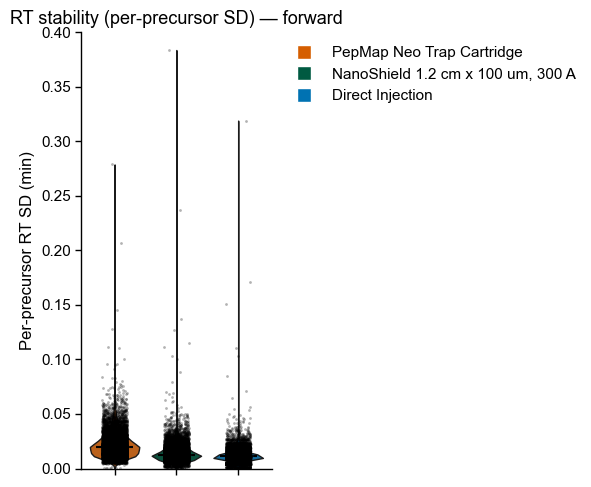

[FORWARD] RT VARIABILITY (SD) — RANKED MOST STABLE -> LEAST STABLE

[forward] By median SD (minutes):
  1. direct_injection             0.011163 min  (most stable)
  2. nanoshield_tht021_flip       0.012688 min  
  3. pepmap                       0.019922 min  (least stable)

[forward] By mean SD (minutes):
  1. direct_injection             0.011523 min  (most stable)
  2. nanoshield_tht021_flip       0.014492 min  
  3. pepmap                       0.021905 min  (least stable)

----------------------------------------------------------------------
[forward] PAIRWISE COMPARISONS (based on median SD, median(diff) direction)
----------------------------------------------------------------------
  pepmap vs nanoshield_tht021_flip:
      median(SD_pepmap - SD_nanoshield_tht021_flip) = +0.006359 min
      --> pepmap is LESS stable than nanoshield_tht021_flip

  pepmap vs direct_injection:
      median(SD_pepmap - SD_direct_injection) = +0.009286 min
      --> pepmap is LESS stable than dire

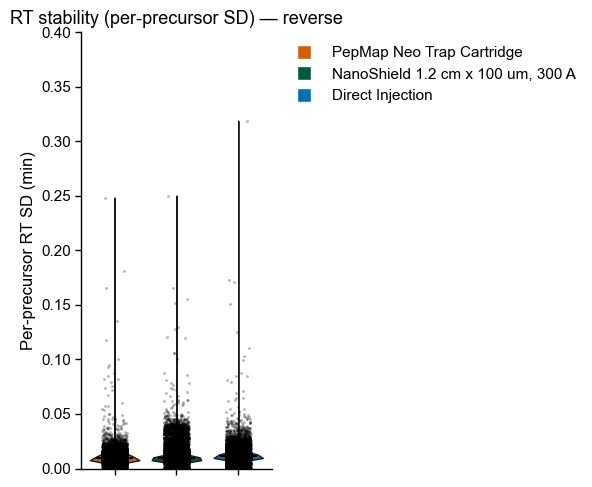

[REVERSE] RT VARIABILITY (SD) — RANKED MOST STABLE -> LEAST STABLE

[reverse] By median SD (minutes):
  1. pepmap                       0.009439 min  (most stable)
  2. nanoshield_tht021_flip       0.009670 min  
  3. direct_injection             0.011262 min  (least stable)

[reverse] By mean SD (minutes):
  1. pepmap                       0.010155 min  (most stable)
  2. direct_injection             0.011817 min  
  3. nanoshield_tht021_flip       0.012101 min  (least stable)

----------------------------------------------------------------------
[reverse] PAIRWISE COMPARISONS (based on median SD, median(diff) direction)
----------------------------------------------------------------------
  pepmap vs nanoshield_tht021_flip:
      median(SD_pepmap - SD_nanoshield_tht021_flip) = -0.000960 min
      --> nanoshield_tht021_flip is LESS stable than pepmap

  pepmap vs direct_injection:
      median(SD_pepmap - SD_direct_injection) = -0.001732 min
      --> direct_injection is LESS stable

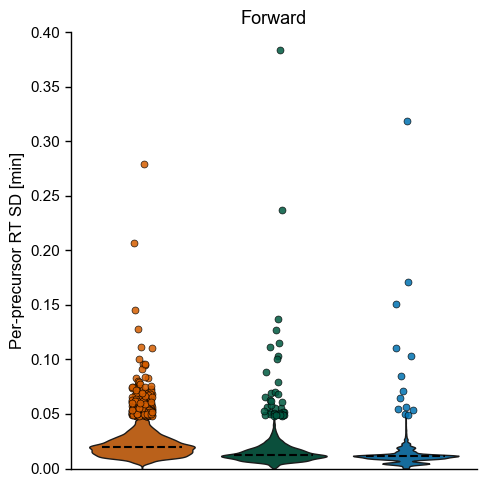

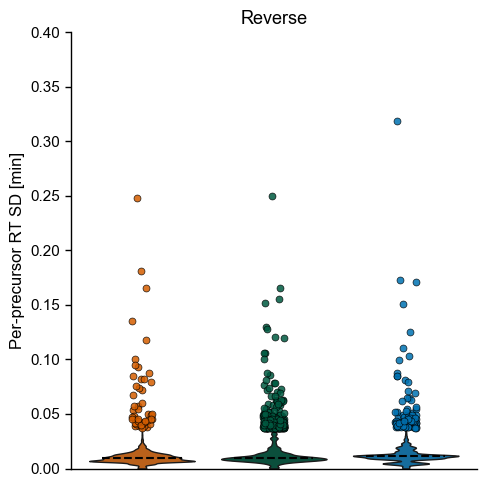

In [6]:
# ══════════════════════════════════════════════════════════════════════════════
# RT STABILITY ANALYSIS & MATCHED VISUALIZATION
# ══════════════════════════════════════════════════════════════════════════════
#
# Purpose:
#   Determine whether retention time (RT) stability (variability) differs
#   across three sample-introduction conditions:
#     - pepmap                  (PepMap Neo Trap Cartridge)
#     - nanoshield_tht021_flip  (NanoShield 1.2 cm x 100 um, 300 A)
#     - direct_injection        (Direct Injection, no trap column)
#
# Statistical approach:
#   1. Collapse the pseudoreplicated pairwise RT_Delta values back down to ONE
#      independent summary statistic per precursor per condition:
#        - SD of the 6 raw RT values -> measures variability/stability.
#      This avoids pseudoreplication (using correlated pairwise differences as
#      if they were independent observations), which would inflate apparent
#      spread and distort p-values.
#   2. Because the same precursors are present in all 3 conditions (paired design),
#      use the Friedman test (non-parametric repeated-measures ANOVA) as the
#      omnibus test on the per-precursor SD distributions. Friedman/Wilcoxon are
#      rank-based and do not require normality, so no normality pre-check is
#      performed — this is doubly appropriate here since SD is a non-negative,
#      right-skewed statistic that is never Gaussian by construction.
#   3. If significant, run post-hoc pairwise Wilcoxon signed-rank tests with
#      Holm correction for multiple comparisons.
#   4. Report effect sizes: Kendall's W (omnibus concordance) and matched-pairs
#      rank-biserial correlation r (pairwise).
#   5. Plot the SAME per-precursor SD values used in the stats (NOT the pairwise
#      RT_Delta values) as violin plots, so the figure matches what the
#      statistics argue. Extreme outlier precursors are shown as individual
#      jittered scatter points rather than stretching the violin/KDE tail.
#
# Note on systematic RT bias:
#   An earlier version of this analysis also tested per-precursor centered mean
#   RT ("bias/shift") against zero via a one-sample Wilcoxon test, framed as a
#   Gaussian-around-zero question. That framing was a leftover from testing
#   pairwise RT_Delta values and no longer applies once the stats operate on
#   SD only (SD has no natural zero-symmetric reference) — this cell now
#   focuses exclusively on RT variability (SD) across conditions.
#
# Color coding:
#   A single source of truth, `condition_config`, maps each internal condition
#   key to (display label, RGB color in 0-1 matplotlib format). ALL plots in
#   this script pull colors from this dictionary — no separate/duplicate
#   color dictionaries are used anywhere, so colors stay consistent across
#   every figure.
#
# Module:
#   All statistical and plotting helper functions, plus the color/label config,
#   plotting style (GraphPad-like), and ALPHA threshold, live in the companion
#   module `retention_time_stability_stats.py` (self-contained — see that file
#   for full docstrings), imported in the first cell of this notebook.
#   All module functions below are called with the `rts.` prefix for clarity
#   and to make the module boundary explicit.
# ══════════════════════════════════════════════════════════════════════════════

# ──────────────────────────────────────────────────────────────────────────────
# DATA PREPARATION: map runs to conditions, filter for globally shared precursors
# ──────────────────────────────────────────────────────────────────────────────

# copy main report so downstream edits never mutate the original dataframes
main_report_pd_fil_for_rt = main_report_pd_fil_for.copy()
main_report_pd_fil_rev_rt = main_report_pd_fil_rev.copy()

# mapping from acquisition date (first 8 chars of Run) to condition name
date_to_condition = {
    "20260911": "pepmap",
    "20260914": "nanoshield_tht021_flip",
    "20260916": "direct_injection"
}

# 1. extract the first 8 characters from the "Run" column (acquisition date) and
#    map these dates to the condition names
main_report_pd_fil_for_rt["Condition"] = main_report_pd_fil_for_rt["Run"].astype(str).str[:8].map(date_to_condition)
main_report_pd_fil_rev_rt["Condition"] = main_report_pd_fil_rev_rt["Run"].astype(str).str[:8].map(date_to_condition)

# 2. apply the globally-shared-precursor filter to forward and reverse datasets
main_report_pd_fil_for_rt_cons = rts.filter_precursors_present_in_all_runs(main_report_pd_fil_for_rt)
main_report_pd_fil_rev_rt_cons = rts.filter_precursors_present_in_all_runs(main_report_pd_fil_rev_rt)
print("Filtering for precursors present in all runs is done - forward:", main_report_pd_fil_for_rt_cons["Precursor.Id"].nunique(), "unique precursors")
print("Filtering for precursors present in all runs is done - reverse:", main_report_pd_fil_rev_rt_cons["Precursor.Id"].nunique(), "unique precursors")

# ──────────────────────────────────────────────────────────────────────────────
# MAIN LOOP: run the SD-based statistical + visualization pipeline for forward
# and reverse datasets separately.
# Uses main_report_pd_fil_for_rt_cons / main_report_pd_fil_rev_rt_cons
# (the RAW RT tables filtered for precursors present in all runs — NOT the
#  exploded pairwise RT_Delta tables, to avoid pseudoreplication).
# ──────────────────────────────────────────────────────────────────────────────

conditions_present = ["pepmap", "nanoshield_tht021_flip", "direct_injection"]

all_results = {}

for flush_label, df_cons in [
    ("forward", main_report_pd_fil_for_rt_cons),
    ("reverse", main_report_pd_fil_rev_rt_cons),
]:
    print(f"\n\n########## {flush_label.upper()} ##########")

    summary = rts.summarize_precursor_condition(df_cons)

    # ---- Variability (SD) comparison ----
    wide_sd = summary.pivot(index="Precursor.Id", columns="Condition", values="SD")
    wide_sd = wide_sd[conditions_present].dropna()
    print(f"\n[{flush_label}] Precursors with complete SD data across all 3 conditions: {wide_sd.shape[0]}")

    sd_stat, sd_p, sd_w, sd_posthoc = rts.friedman_and_posthoc(
        wide_sd, conditions_present, f"{flush_label} — RT variability (SD)"
    )

    # ---- plot the SAME SD data used for the stats above ----
    rts.plot_sd_violin(wide_sd, conditions_present, flush_label)

    # ---- ranking / direction-of-effect printout for THIS flush ----
    rts.print_stability_ranking(wide_sd, conditions_present, flush_label)

    all_results[flush_label] = {
        "wide_sd": wide_sd,
        "sd_friedman_p": sd_p, "sd_kendalls_w": sd_w, "sd_posthoc": sd_posthoc,
    }

# ──────────────────────────────────────────────────────────────────────────────
# Minimal clean violin plots (one per flush), outliers shown as scatter points
# ──────────────────────────────────────────────────────────────────────────────
rts.plot_sd_violin_clean(all_results["forward"]["wide_sd"], conditions_present, "forward")
rts.plot_sd_violin_clean(all_results["reverse"]["wide_sd"], conditions_present, "reverse")